In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/questions.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/qid2analysis_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/cid2content_emb.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_window_sequences_quelevel.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/test.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/kc_routes_map.json
/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv
/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv


In [2]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm   # thêm dòng này
from torch.nn.init import kaiming_normal_

# 1. Config


In [3]:
config = {
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv",
    "num_concepts": 865,
    "size_m": 50,
    "dim_s": 100,
    "hidden_dim": 200,
    "dropout": 0.2,
    "lr": 0.02,
    "batch_size": 100,
    "num_epochs": 100,
    "patience": 100,
}

# 2. Data Loading

In [4]:
df_train_valid = pd.read_csv(config['data_train_valid_path'])
df_test = pd.read_csv(config['data_test_path'])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")

Train: 33397
Test: 697697


# 3. Dataset & DataLoader

In [5]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class DKVMNDataset(Dataset):
    def __init__(self, df, num_concepts, fold=None, is_train=True):

        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold] 
        
        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks= [parse_seq(x) for x in df['selectmasks']]

        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )
        self.num_concepts = num_concepts
        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        c = torch.tensor(self.concepts[i], dtype=torch.long).clamp(min=0)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)

        item = {
            "concepts": c,
            "responses": r,
            "selectmasks": m
        }
        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)
        return item

# 4. Model Definition


In [6]:
class DKVMN(nn.Module):
    def __init__(self, num_concepts, dim_s, size_m, dropout=0.2):
        super().__init__()
        self.num_concepts = num_concepts
        self.dim_s = dim_s
        self.size_m = size_m
        self.k_emb_layer = nn.Embedding(self.num_concepts, self.dim_s)
        self.Mk = nn.Parameter(torch.Tensor(self.size_m, self.dim_s))
        self.Mv0 = nn.Parameter(torch.Tensor(self.size_m, self.dim_s))
        kaiming_normal_(self.Mk)
        kaiming_normal_(self.Mv0)
        self.v_emb_layer = nn.Embedding(self.num_concepts * 2, self.dim_s)
        self.f_layer = nn.Linear(self.dim_s * 2, self.dim_s)
        self.dropout_layer = nn.Dropout(dropout)
        self.p_layer = nn.Linear(self.dim_s, 1)
        self.e_layer = nn.Linear(self.dim_s, self.dim_s)
        self.a_layer = nn.Linear(self.dim_s, self.dim_s)
    def forward(self, c, r):
        # c, r: (batch_size, seq_len)
        batch_size = c.shape[0]
        x = c + self.num_concepts * r # (batch_size, seq_len)
        k = self.k_emb_layer(c) # (batch_size, seq_len, dim_s)
        v = self.v_emb_layer(x) # (batch_size, seq_len, dim_s)
        Mvt = self.Mv0.unsqueeze(0).repeat(batch_size, 1, 1) # (batch_size, size_m, dim_s)
        Mv = [Mvt]
        w = torch.softmax(torch.matmul(k, self.Mk.T), dim=-1) # (batch_size, seq_len, size_m)
        # Write Process
        e = torch.sigmoid(self.e_layer(v)) # (batch_size, seq_len, dim_s)
        a = torch.tanh(self.a_layer(v)) # (batch_size, seq_len, dim_s)

        for et, at, wt in zip (
            e.permute(1, 0, 2), a.permute(1, 0, 2), w.permute(1, 0, 2)
        ):
            # e.permute (seq_len, batch_size, dim_s)
            # a.permute (seq_len, batch_size, dim_s)
            # w.permute (seq_len, batch_size, size_m)
            # et (batch_size, dim_s)
            # at (batch_size, dim_s)
            # wt (batch_size, size_m)
            # wt.unsqeeze(-1) (batch_size, size_m, 1)
            # et.unsqeeze(1) (batch_size, 1, dim_s)
            Mvt = Mvt * (1 - (wt.unsqueeze(-1) * et.unsqueeze(1))) + (wt.unsqueeze(-1) * at.unsqueeze(1))
            Mv.append(Mvt)

        Mv = torch.stack(Mv, dim=1) # (batch_size, seq_len + 1, size_m, dim_s)
        f = torch.tanh(
            self.f_layer(
                torch.cat(
                    [
                        (w.unsqueeze(-1) * Mv[:, :-1]).sum(-2), # (batch_size, seq_len, dim_s)
                        k
                    ],
                    dim=-1
                ) # (batch_size, seq_len, 2 * dim_s)
            )# (batch_size, seq_len, dim_s)
        )
        p = self.p_layer(self.dropout_layer(f)) #(batch_size, seq_len, 1)
        p = p.squeeze(-1) # (batch_size, seq_len)
        return p
            
        
        
        
        

# 5. Compute Metric

In [7]:
from collections import defaultdict
import numpy as np
import torch
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, accuracy_score, mean_squared_error, mean_absolute_error, f1_score, precision_score, recall_score

def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_pred_binary = (y_pred > 0.5).astype(int)

    if len(np.unique(y_true)) > 1:
        auc = roc_auc_score(y_true, y_pred)
    else:
        auc = 0.5

    acc = accuracy_score(y_true, y_pred_binary)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    f1 = f1_score(y_true, y_pred_binary, zero_division=0)
    precision = precision_score(y_true, y_pred_binary, zero_division=0)
    recall = recall_score(y_true, y_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "mae": mae,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# 6. Train Loop

In [8]:
def train_epoch(model, train_loader, val_loader, optimizer, scheduler, device, num_epochs=20, patience=5):
    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []

    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # TRAIN
        model.train()
        total_loss = 0.0
        n_batches = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            optimizer.zero_grad(set_to_none=True)
            logits = model(concepts, responses) # (batch_size, seq_len)

            valid = selectmasks == 1
            loss_fn = torch.nn.BCEWithLogitsLoss()
            loss = loss_fn(logits[valid], responses[valid].float())
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=50.0)
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
            pbar.set_postfix(loss=loss.item())
        avg_train_loss = total_loss / n_batches
        train_loss_history.append(avg_train_loss)
        scheduler.step()
        # VALID
        model.eval()
        val_total_loss = 0.0
        val_batches = 0
        with torch.no_grad():
            for batch in val_loader:
                concepts = batch["concepts"].to(device)
                responses = batch["responses"].to(device)
                selectmasks = batch["selectmasks"].to(device)

                logits = model(concepts, responses)
                valid = selectmasks == 1
                loss_fn = torch.nn.BCEWithLogitsLoss()
                loss = loss_fn(logits[valid], responses[valid].float())
                val_total_loss += loss.item()
                val_batches +=1
        avg_val_loss = val_total_loss / val_batches
        valid_loss_history.append(avg_val_loss)

        val_metrics = evaluate(model, val_loader, device, question_level=False)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
              f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
              f"val_acc={val_metrics['acc']:.4f}")

        # EARLT STOPPING
        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break
    # load lại best checkpoint theo val AUC
    if best_state is not None:
        model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }
    return model, history
        
            

# 7. Evaluate

In [9]:
def evaluate(model, loader, device, question_level=True):
    model.eval()
    if question_level:
        preds = defaultdict(list)
        labels = defaultdict(list)
    else:
        all_preds = []
        all_labels = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)
            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset không có 'qidxs' nên không thể eval ở mức question.")
            logits = model(concepts, responses)
            probs = torch.sigmoid(logits)
            if question_level:
                qidxs = batch["qidxs"]
                pred_cpu = probs.cpu()
                target_cpu = responses.cpu()
                mask_cpu = selectmasks.cpu()
                qid_cpu = qidxs.cpu()

                batch_size, seq_len = pred_cpu.shape
                for i in range(batch_size):
                    for t in range(seq_len):
                        if mask_cpu[i, t] == 1:
                            qid = qid_cpu[i, t].item()
                            preds[qid].append(pred_cpu[i, t].item())
                            labels[qid].append(target_cpu[i, t].item())
            else:
                valid = selectmasks == 1
                all_preds.extend(probs[valid].cpu().numpy().tolist())
                all_labels.extend(responses[valid].cpu().numpy().tolist())
    if question_level:
        final_pred, final_true = [], []
        for k in preds:
            final_pred.append(sum(preds[k]) / len(preds[k]))          # trung bình dự đoán của mọi lần xuất hiện qid k
            final_true.append(round(sum(labels[k]) / len(labels[k]))) # trung bình nhãn thực (thường sẽ giống nhau cho cùng 1 qid)
        return compute_metrics(final_true, final_pred)
    else:
        return compute_metrics(all_labels, all_preds)

# 8. Training & Evaluating


FOLD 0


Epoch 1: train_loss=0.5091, val_loss=0.4963, val_auc=0.6055, val_acc=0.7955


Epoch 2: train_loss=0.4926, val_loss=0.4848, val_auc=0.6478, val_acc=0.7959


Epoch 3: train_loss=0.4817, val_loss=0.4754, val_auc=0.6713, val_acc=0.7981


Epoch 4: train_loss=0.4748, val_loss=0.4709, val_auc=0.6821, val_acc=0.7992


...

Epoch 96: train_loss=0.4300, val_loss=0.4288, val_auc=0.7599, val_acc=0.8141


Epoch 97: train_loss=0.4299, val_loss=0.4288, val_auc=0.7599, val_acc=0.8142


Epoch 98: train_loss=0.4297, val_loss=0.4287, val_auc=0.7599, val_acc=0.8142


Epoch 99: train_loss=0.4300, val_loss=0.4287, val_auc=0.7600, val_acc=0.8143


Epoch 100: train_loss=0.4297, val_loss=0.4286, val_auc=0.7603, val_acc=0.8143


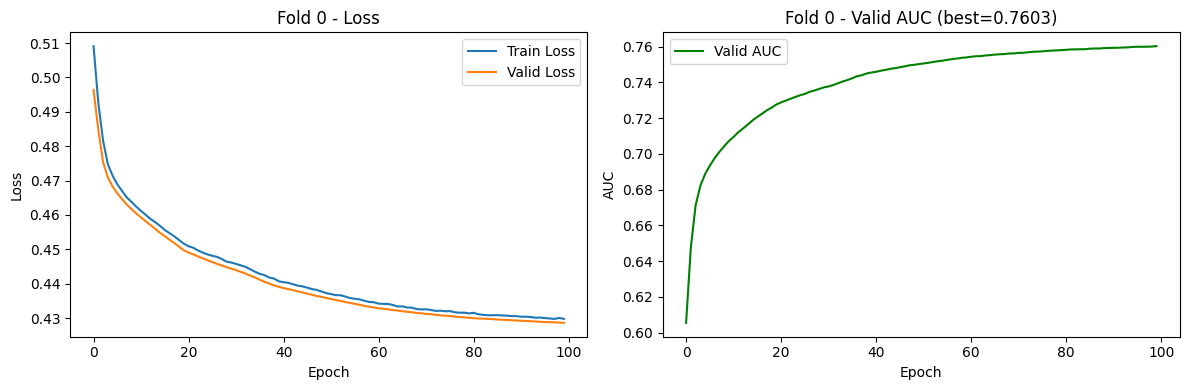

Fold 0 xong. Best valid AUC = 0.7603

FOLD 1


Epoch 1: train_loss=0.5125, val_loss=0.4949, val_auc=0.6053, val_acc=0.7970


Epoch 2: train_loss=0.4925, val_loss=0.4818, val_auc=0.6521, val_acc=0.7976


Epoch 3: train_loss=0.4799, val_loss=0.4716, val_auc=0.6758, val_acc=0.8003


Epoch 4: train_loss=0.4737, val_loss=0.4680, val_auc=0.6844, val_acc=0.8011


...

Epoch 96: train_loss=0.4337, val_loss=0.4304, val_auc=0.7553, val_acc=0.8139


Epoch 97: train_loss=0.4337, val_loss=0.4302, val_auc=0.7555, val_acc=0.8139


Epoch 98: train_loss=0.4335, val_loss=0.4301, val_auc=0.7556, val_acc=0.8141


Epoch 99: train_loss=0.4335, val_loss=0.4300, val_auc=0.7559, val_acc=0.8142


Epoch 100: train_loss=0.4332, val_loss=0.4299, val_auc=0.7559, val_acc=0.8142


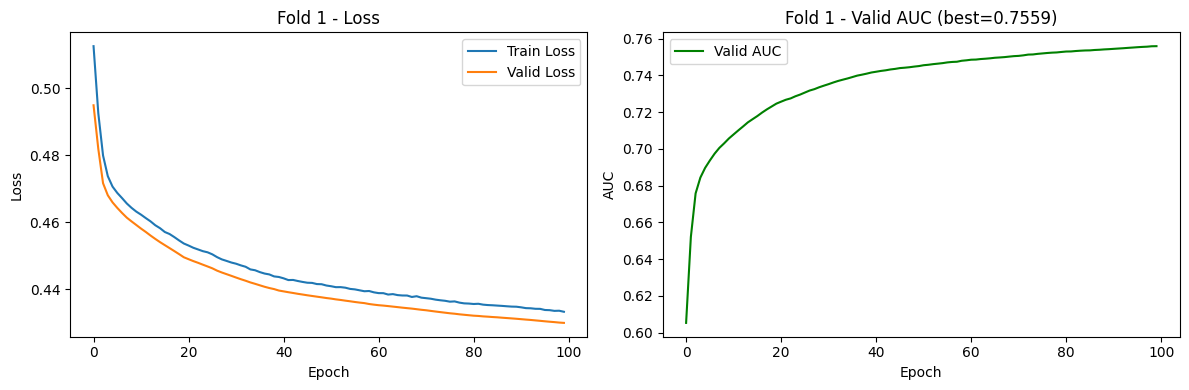

Fold 1 xong. Best valid AUC = 0.7559

FOLD 2


Epoch 1: train_loss=0.5097, val_loss=0.4999, val_auc=0.6078, val_acc=0.7926


Epoch 2: train_loss=0.4912, val_loss=0.4876, val_auc=0.6521, val_acc=0.7930


Epoch 3: train_loss=0.4811, val_loss=0.4782, val_auc=0.6729, val_acc=0.7956


Epoch 4: train_loss=0.4756, val_loss=0.4743, val_auc=0.6826, val_acc=0.7966


...

Epoch 96: train_loss=0.4297, val_loss=0.4296, val_auc=0.7646, val_acc=0.8125


Epoch 97: train_loss=0.4298, val_loss=0.4295, val_auc=0.7649, val_acc=0.8125


Epoch 98: train_loss=0.4296, val_loss=0.4294, val_auc=0.7649, val_acc=0.8126


Epoch 99: train_loss=0.4295, val_loss=0.4293, val_auc=0.7649, val_acc=0.8126


Epoch 100: train_loss=0.4295, val_loss=0.4292, val_auc=0.7651, val_acc=0.8127


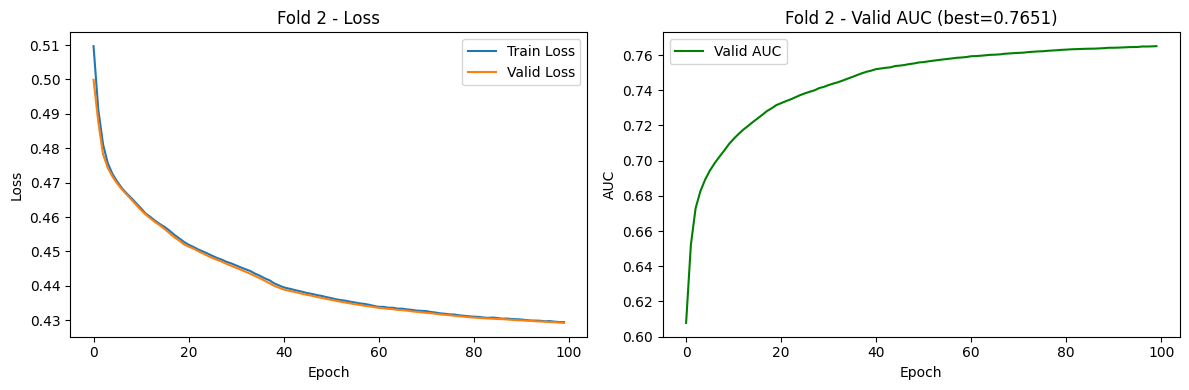

Fold 2 xong. Best valid AUC = 0.7651

FOLD 3


Epoch 1: train_loss=0.5093, val_loss=0.4916, val_auc=0.6177, val_acc=0.7976


Epoch 2: train_loss=0.4896, val_loss=0.4773, val_auc=0.6619, val_acc=0.7987


Epoch 3: train_loss=0.4788, val_loss=0.4703, val_auc=0.6774, val_acc=0.8007


Epoch 4: train_loss=0.4742, val_loss=0.4674, val_auc=0.6850, val_acc=0.8012


...

Epoch 96: train_loss=0.4343, val_loss=0.4297, val_auc=0.7568, val_acc=0.8141


Epoch 97: train_loss=0.4339, val_loss=0.4296, val_auc=0.7570, val_acc=0.8141


Epoch 98: train_loss=0.4342, val_loss=0.4295, val_auc=0.7572, val_acc=0.8141


Epoch 99: train_loss=0.4340, val_loss=0.4294, val_auc=0.7573, val_acc=0.8142


Epoch 100: train_loss=0.4339, val_loss=0.4293, val_auc=0.7574, val_acc=0.8142


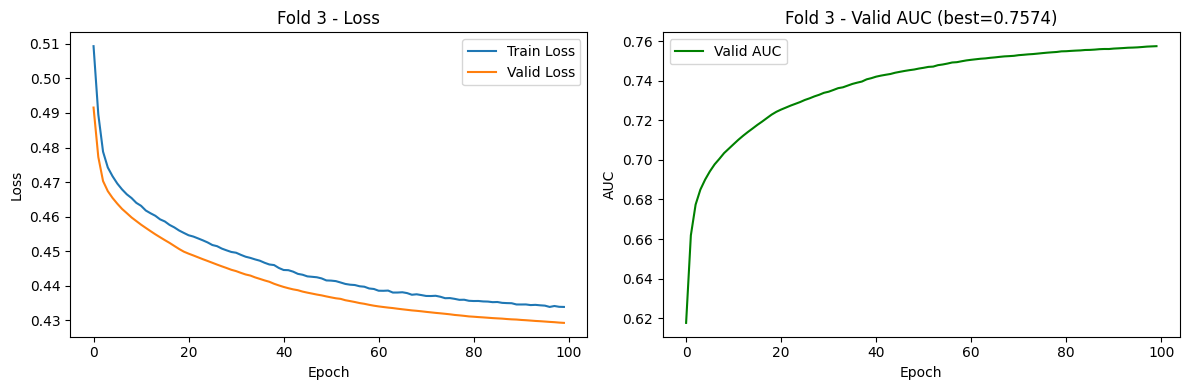

Fold 3 xong. Best valid AUC = 0.7574

FOLD 4


Epoch 1: train_loss=0.5099, val_loss=0.4951, val_auc=0.6136, val_acc=0.7953


Epoch 2: train_loss=0.4913, val_loss=0.4836, val_auc=0.6521, val_acc=0.7959


Epoch 3: train_loss=0.4814, val_loss=0.4750, val_auc=0.6737, val_acc=0.7977


Epoch 4: train_loss=0.4756, val_loss=0.4709, val_auc=0.6839, val_acc=0.7984


...

Epoch 96: train_loss=0.4292, val_loss=0.4276, val_auc=0.7625, val_acc=0.8142


Epoch 97: train_loss=0.4290, val_loss=0.4276, val_auc=0.7626, val_acc=0.8143


Epoch 98: train_loss=0.4291, val_loss=0.4275, val_auc=0.7626, val_acc=0.8143


Epoch 99: train_loss=0.4291, val_loss=0.4274, val_auc=0.7628, val_acc=0.8143


Epoch 100: train_loss=0.4290, val_loss=0.4274, val_auc=0.7628, val_acc=0.8143


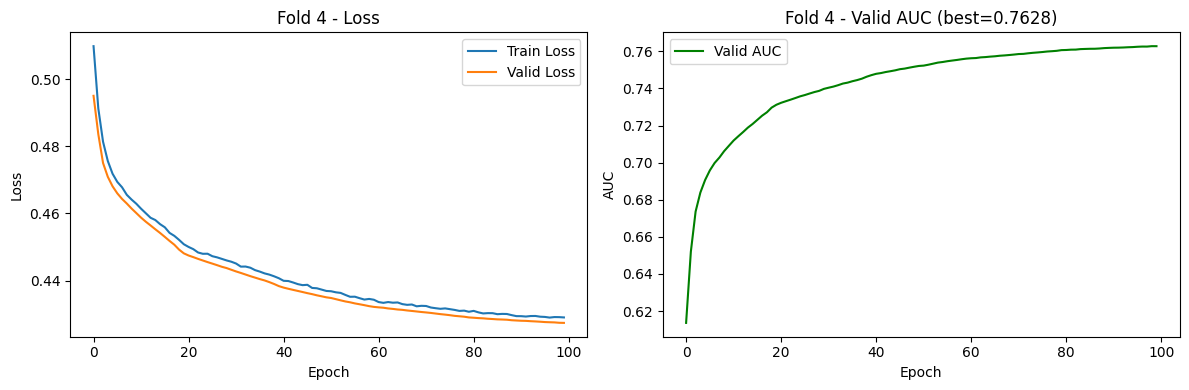

Fold 4 xong. Best valid AUC = 0.7628


In [10]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []       # giữ 5 model đã train xong, ngay trong RAM
all_histories = []        # giữ lịch sử loss/auc từng fold để vẽ biểu đồ
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
for i in range(5):
    print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

    # ---- Chuẩn bị data ----
    train_dataset = DKVMNDataset(df_train_valid, config['num_concepts'], fold=i, is_train=True)
    valid_dataset = DKVMNDataset(df_train_valid, config['num_concepts'], fold=i, is_train=False)
    train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

    # ---- Khởi tạo model mới (random init) cho mỗi fold ----
    model = DKVMN(
        num_concepts=config['num_concepts'],
        dim_s = config.get('dim_s', 100),
        size_m=config.get('size_m', 50),
        dropout=config.get('dropout', 0.2)
    ).to(device)

    optimizer = torch.optim.SGD(
        model.parameters(), lr=config['lr'], momentum=0.9
    )
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=1/1.5)

    # ---- Train fold này ----
    model, history = train_epoch(
        model, train_loader, valid_loader, optimizer, scheduler, device,
        num_epochs=config.get('num_epochs', 50),
        patience=config.get('patience', 5)
    )

    trained_models.append(model)     # lưu model (đã load best checkpoint) vào RAM
    all_histories.append(history)

    # ---- Vẽ biểu đồ cho fold này ----
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["valid_loss"], label="Valid Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Fold {i} - Loss")
    axes[0].legend()

    axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
    axes[1].legend()

    plt.tight_layout()
    plt.show()          # hiển thị trực tiếp trong Kaggle notebook, không cần lưu file

    print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")

In [11]:
test_dataset = DKVMNDataset(df_test, config['num_concepts'], fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

test_results = []

for i, model in enumerate(trained_models):
    metrics = evaluate(model, test_loader, device, question_level=True)  # bật True nếu df_test có cột qidxs
    metrics["fold"] = i
    test_results.append(metrics)
    print(f"Fold {i} - Test: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items() if k != "fold"))

Fold 0 - Test: auc=0.7392, acc=0.8045, rmse=0.3770, mae=0.2779, f1=0.8870, precision=0.8208, recall=0.9649


Fold 1 - Test: auc=0.7381, acc=0.8048, rmse=0.3770, mae=0.2771, f1=0.8874, precision=0.8200, recall=0.9668


Fold 2 - Test: auc=0.7378, acc=0.8045, rmse=0.3772, mae=0.2774, f1=0.8872, precision=0.8198, recall=0.9667


Fold 3 - Test: auc=0.7380, acc=0.8041, rmse=0.3773, mae=0.2781, f1=0.8870, precision=0.8197, recall=0.9664


Fold 4 - Test: auc=0.7386, acc=0.8043, rmse=0.3771, mae=0.2779, f1=0.8870, precision=0.8203, recall=0.9655


In [12]:
import numpy as np

metric_names = ["auc", "acc", "rmse", "mae", "f1", "precision", "recall"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")


TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.7383 ± 0.0005
ACC       : 0.8044 ± 0.0002
RMSE      : 0.3771 ± 0.0001
MAE       : 0.2777 ± 0.0004
F1        : 0.8871 ± 0.0002
PRECISION : 0.8201 ± 0.0004
RECALL    : 0.9661 ± 0.0007


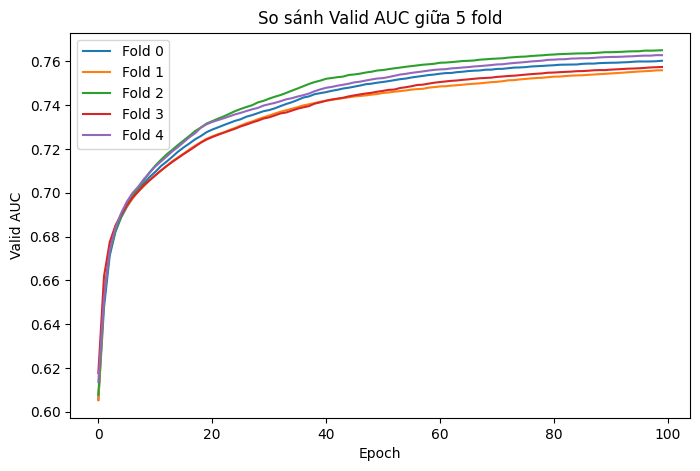

In [13]:
plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()